In [1]:
import gc
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
FILE = "GSE40279_series_matrix.txt.gz"

In [2]:
!wget -nc https://ftp.ncbi.nlm.nih.gov/geo/series/GSE40nnn/GSE40279/matrix/GSE40279_series_matrix.txt.gz

--2026-11-22 16:30:59--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE40nnn/GSE40279/matrix/GSE40279_series_matrix.txt.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.12, 130.14.250.13, 2607:f220:41e:250::13, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.12|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1237679628 (1.2G) [application/x-gzip]
Saving to: ‘GSE40279_series_matrix.txt.gz’

GSE40279_series_mat 100%[===================>]   1.15G   102MB/s    in 16s     

2026-11-22 16:31:15 (73.4 MB/s) - ‘GSE40279_series_matrix.txt.gz’ saved [1237679628/1237679628]



In [3]:
sample_ids, characteristics, table_start = None, [], None
with gzip.open(FILE, "rt") as f:
    for i, line in enumerate(f):
        if line.startswith("!Sample_geo_accession"):
            sample_ids = [x.strip('"') for x in line.rstrip("\n").split("\t")[1:]]
        elif line.startswith("!Sample_characteristics_ch1"):
            characteristics.append([x.strip('"') for x in line.rstrip("\n").split("\t")[1:]])
        elif line.startswith("!series_matrix_table_begin"):
            table_start = i + 1
            break

meta = {}
for row in characteristics:
    for j, entry in enumerate(row):
        if ": " in entry:
            key, value = entry.split(": ", 1)
            meta.setdefault(key, [None] * len(row))[j] = value
meta = pd.DataFrame(meta, index=sample_ids)

age_col = [c for c in meta.columns if c.lower().startswith("age")][0]
sex_col = [c for c in meta.columns if c.lower() in ("gender", "sex")][0]
plate_col = [c for c in meta.columns if "plate" in c.lower()]

meta["age"] = pd.to_numeric(meta[age_col])
meta["sex"] = meta[sex_col]
meta["plate"] = meta[plate_col[0]] if plate_col else "unknown"
meta[["age", "sex", "plate"]].describe(include="all")

,age,sex,plate
count,656.000000,656,656
unique,NaN,2,9
top,NaN,F,6
freq,NaN,338,92
mean,64.035061,NaN,NaN
std,14.736681,NaN,NaN
min,19.000000,NaN,NaN
25%,54.000000,NaN,NaN
50%,65.000000,NaN,NaN
75%,75.000000,NaN,NaN


In [4]:
blocks, cpg_ids = [], []
for chunk in pd.read_csv(FILE, sep="\t", skiprows=table_start, index_col=0,
                         dtype={s: np.float32 for s in sample_ids}, chunksize=20000):
    chunk = chunk[~chunk.index.str.startswith("!")]
    chunk = chunk[chunk.isna().mean(axis=1) <= 0.05]
    blocks.append(chunk[meta.index].to_numpy(dtype=np.float32))
    cpg_ids.extend(chunk.index)

values = np.vstack(blocks)
del blocks
gc.collect()

missing = np.isnan(values)
if missing.any():
    medians = np.nanmedian(values, axis=1)
    rows, cols = np.where(missing)
    values[rows, cols] = medians[rows]
del missing

keep = values.std(axis=1) > 0
beta = pd.DataFrame(values[keep], index=np.array(cpg_ids)[keep], columns=meta.index)
del values, cpg_ids, keep
gc.collect()
print(beta.shape)

(473034, 656)


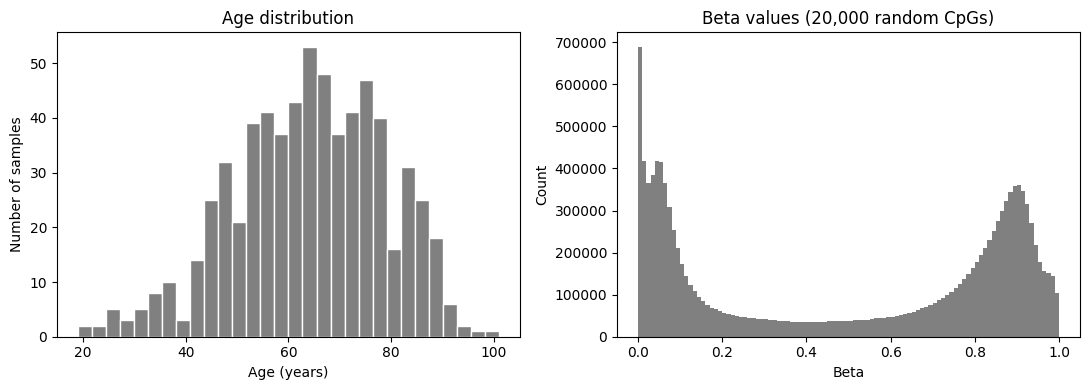

sex
F    338
M    318
Name: count, dtype: int64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(meta["age"], bins=30, color="grey", edgecolor="white")
ax[0].set(title="Age distribution", xlabel="Age (years)", ylabel="Number of samples")
sample_vals = beta.sample(n=min(20000, len(beta)), random_state=SEED).values.ravel()
ax[1].hist(sample_vals, bins=100, color="grey")
ax[1].set(title="Beta values (20,000 random CpGs)", xlabel="Beta", ylabel="Count")
plt.tight_layout()
plt.show()
print(meta["sex"].value_counts())

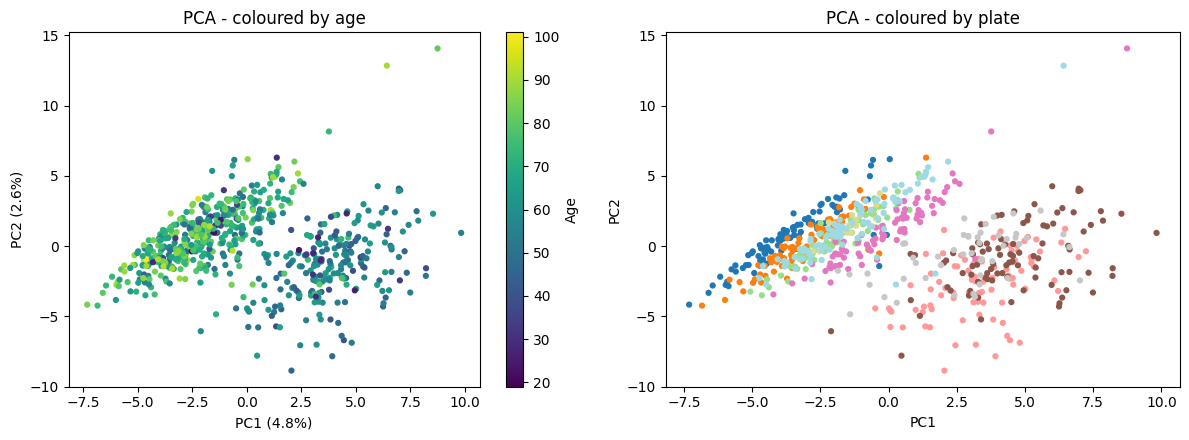

PC1 vs age: r = -0.43
PC2 vs age: r = +0.19
PC3 vs age: r = +0.04
PC4 vs age: r = +0.10
PC5 vs age: r = +0.07


In [6]:
top_var = beta.var(axis=1).nlargest(10000).index
pca = PCA(n_components=5, random_state=SEED).fit(beta.loc[top_var].T)
X_pca = pca.transform(beta.loc[top_var].T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
s = ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=meta["age"], cmap="viridis", s=12)
plt.colorbar(s, ax=ax[0], label="Age")
ax[0].set(title="PCA - coloured by age",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=pd.factorize(meta["plate"])[0], cmap="tab20", s=12)
ax[1].set(title="PCA - coloured by plate", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()

for k in range(5):
    print(f"PC{k+1} vs age: r = {np.corrcoef(X_pca[:, k], meta['age'])[0, 1]:+.2f}")

In [7]:
X = beta.T
y = meta["age"].values
age_group = pd.cut(y, bins=[0, 30, 40, 50, 60, 70, 80, 200], labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=age_group)
del beta, X
gc.collect()

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Mean age  train: {y_train.mean():.1f}  test: {y_test.mean():.1f}")

Train: (459, 473034)  Test: (197, 473034)
Mean age  train: 64.0  test: 64.2


cg16867657    0.861
cg24724428    0.749
cg22454769    0.745
cg06639320    0.726
cg10501210   -0.722
cg08234504   -0.708
cg07553761    0.699
cg24079702    0.691
cg21572722    0.681
cg19283806   -0.674
dtype: float32


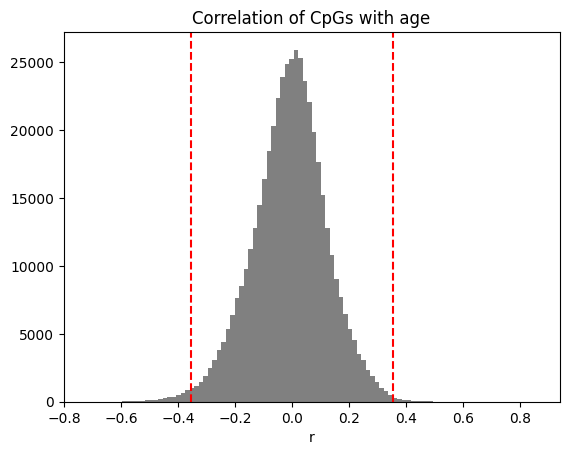

In [8]:
Xt = X_train.to_numpy(dtype=np.float32)
yc = (y_train - y_train.mean()).astype(np.float32)
r = np.empty(Xt.shape[1], dtype=np.float32)
step = 50000
for s in range(0, Xt.shape[1], step):
    block = Xt[:, s:s+step]
    block = block - block.mean(axis=0)
    r[s:s+step] = (block * yc[:, None]).sum(axis=0) / (
        np.sqrt((block**2).sum(axis=0)) * np.sqrt((yc**2).sum()))
del Xt, block
gc.collect()

corr = pd.Series(r, index=X_train.columns).dropna()
selected = corr.abs().nlargest(5000).index
print(corr.loc[corr.abs().nlargest(10).index].round(3))

cutoff = corr.loc[selected].abs().min()
plt.hist(corr, bins=100, color="grey")
plt.axvline(cutoff, color="red", ls="--")
plt.axvline(-cutoff, color="red", ls="--")
plt.title("Correlation of CpGs with age")
plt.xlabel("r")
plt.show()

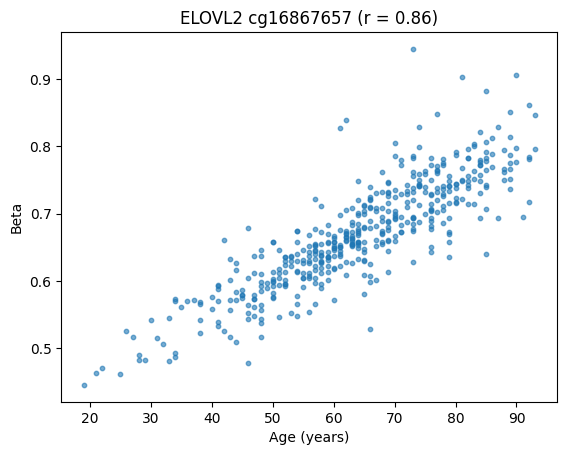

Rank: 1


In [9]:
if "cg16867657" in X_train.columns:
    plt.scatter(y_train, X_train["cg16867657"], s=10, alpha=0.6)
    plt.xlabel("Age (years)")
    plt.ylabel("Beta")
    plt.title(f"ELOVL2 cg16867657 (r = {corr['cg16867657']:.2f})")
    plt.show()
    print("Rank:", int((corr.abs() > abs(corr["cg16867657"])).sum()) + 1)

In [10]:
model = make_pipeline(
    StandardScaler(),
    ElasticNetCV(l1_ratio=0.5, cv=10, random_state=SEED, n_jobs=-1, max_iter=5000))
model.fit(X_train[selected], y_train)

enet = model[-1]
coefs = pd.Series(enet.coef_, index=selected)
coefs = coefs[coefs != 0].sort_values(key=abs, ascending=False)
print(f"Alpha: {enet.alpha_:.4f}")
print(f"CpGs in model: {len(coefs)} / {len(selected)}")
coefs.head(15).round(3)

Alpha: 0.4143
CpGs in model: 327 / 5000


,0
cg16867657,0.699
cg15707833,0.594
cg08097417,0.499
cg21186299,0.490
cg14361627,0.411
cg20300246,0.384
cg00246121,-0.378
cg17621438,-0.369
cg23615741,-0.367
cg04400972,0.339


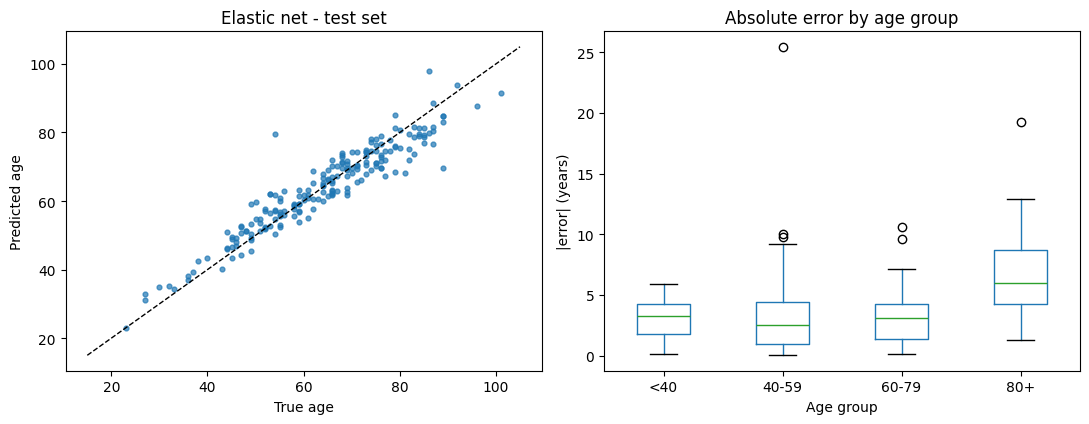

       mean  count
group             
<40    2.98     11
40-59  3.35     67
60-79  3.11     92
80+    6.59     27


,MAE (years),RMSE (years),r
Elastic net (327 CpGs),3.66,4.89,0.95


In [11]:
def evaluate(true, pred, name):
    return pd.Series({
        "MAE (years)": mean_absolute_error(true, pred),
        "RMSE (years)": np.sqrt(mean_squared_error(true, pred)),
        "r": np.corrcoef(true, pred)[0, 1]}, name=name)

pred_enet = model.predict(X_test[selected])
results = [evaluate(y_test, pred_enet, f"Elastic net ({len(coefs)} CpGs)")]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test, pred_enet, s=12, alpha=0.7)
ax[0].plot([15, 105], [15, 105], "k--", lw=1)
ax[0].set(xlabel="True age", ylabel="Predicted age", title="Elastic net - test set")

errors = pd.DataFrame({
    "group": pd.cut(y_test, [0, 40, 60, 80, 200], labels=["<40", "40-59", "60-79", "80+"]),
    "abs_error": np.abs(pred_enet - y_test)})
errors.boxplot(column="abs_error", by="group", ax=ax[1], grid=False)
ax[1].set(title="Absolute error by age group", xlabel="Age group", ylabel="|error| (years)")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(errors.groupby("group", observed=True)["abs_error"].agg(["mean", "count"]).round(2))
pd.DataFrame(results).round(2)

In [12]:
panel = {"cg16867657": "ELOVL2", "cg10501210": "C1orf132", "cg07553761": "TRIM59",
         "cg14361627": "KLF14", "cg06639320": "FHL2"}
available = [c for c in panel if c in X_train.columns]
print(corr.reindex(available).round(3).rename(index=panel))

panel_model = LinearRegression().fit(X_train[available], y_train)
pred_panel = panel_model.predict(X_test[available])
results.append(evaluate(y_test, pred_panel, f"Forensic panel ({len(available)} CpGs)"))

if "cg16867657" in available:
    elovl2_model = LinearRegression().fit(X_train[["cg16867657"]], y_train)
    results.append(evaluate(y_test, elovl2_model.predict(X_test[["cg16867657"]]), "ELOVL2 only (1 CpG)"))

table = pd.DataFrame(results).round(2)
table

ELOVL2      0.861
C1orf132   -0.722
TRIM59      0.699
KLF14       0.584
FHL2        0.726
dtype: float32


,MAE (years),RMSE (years),r
Elastic net (327 CpGs),3.66,4.89,0.95
Forensic panel (5 CpGs),4.34,5.54,0.93
ELOVL2 only (1 CpG),5.94,7.65,0.85


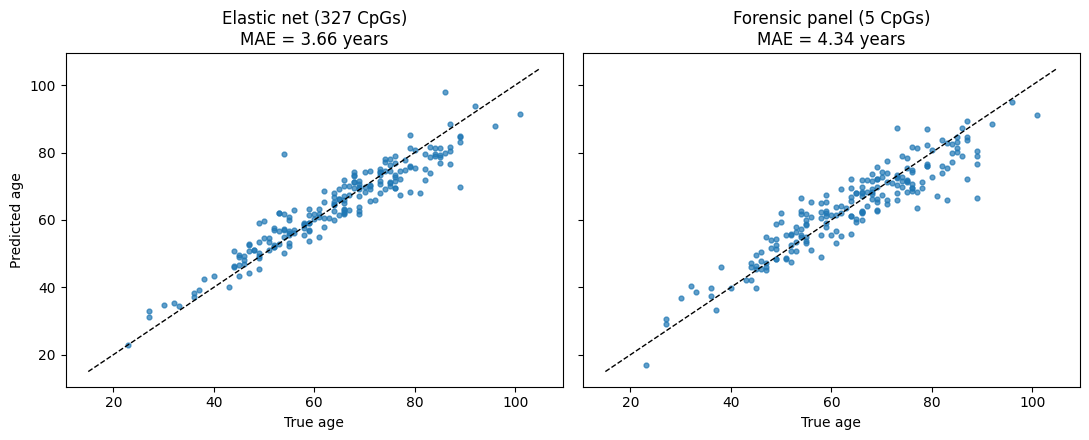

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, pred, name in [(ax[0], pred_enet, table.index[0]), (ax[1], pred_panel, table.index[1])]:
    a.scatter(y_test, pred, s=12, alpha=0.7)
    a.plot([15, 105], [15, 105], "k--", lw=1)
    a.set(title=f"{name}\nMAE = {mean_absolute_error(y_test, pred):.2f} years", xlabel="True age")
ax[0].set_ylabel("Predicted age")
plt.tight_layout()
plt.show()